# KNN Classification with the Wine Dataset
#### Aim: Predict wine class from 13 chemical measurements using K-Nearest Neighbors (KNN).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

### 1. Load the data

In [2]:
wine = load_wine(as_frame= True)

In [3]:
X = wine.data
y = wine.target

In [4]:
df = wine.frame

### 2. Explore the dataset
Inspect the dataset's size, sample rows, target classes, and class counts.

In [5]:
print("Dataset shape:", df.shape)
print("\n First 5 rows:")
display(df.head())

Dataset shape: (178, 14)

 First 5 rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [6]:
print("Target classes:")
print(wine.target_names)

Target classes:
['class_0' 'class_1' 'class_2']


In [7]:
print("Class Distribution:")
print(y.value_counts().sort_index())

Class Distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64


#### 2.1 Check data quality
Check data types, missing values, and duplicate rows.

In [8]:
print("Data types:")
print(df.dtypes)

Data types:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object


In [9]:
print("Missing values:")
print(df.isnull().sum().sum())

Missing values:
0


In [10]:
print("Duplicated values:")
print(df.duplicated().sum())

Duplicated values:
0


#### 2.2 Summarize the features


In [11]:
print("Feature Summary:")
display(X.describe().T)

Feature Summary:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


#### 2.3 Class distribution

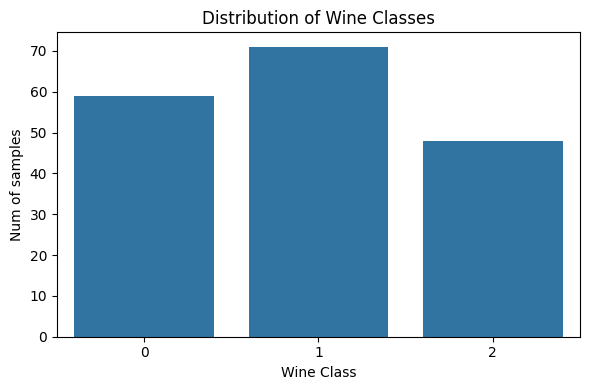

In [12]:
plt.figure(figsize=(6,4))

sns.countplot(x=y)

plt.title("Distribution of Wine Classes")
plt.xlabel("Wine Class")
plt.ylabel("Num of samples")

plt.tight_layout()
plt.show()

#### 2.4 Example feature scales

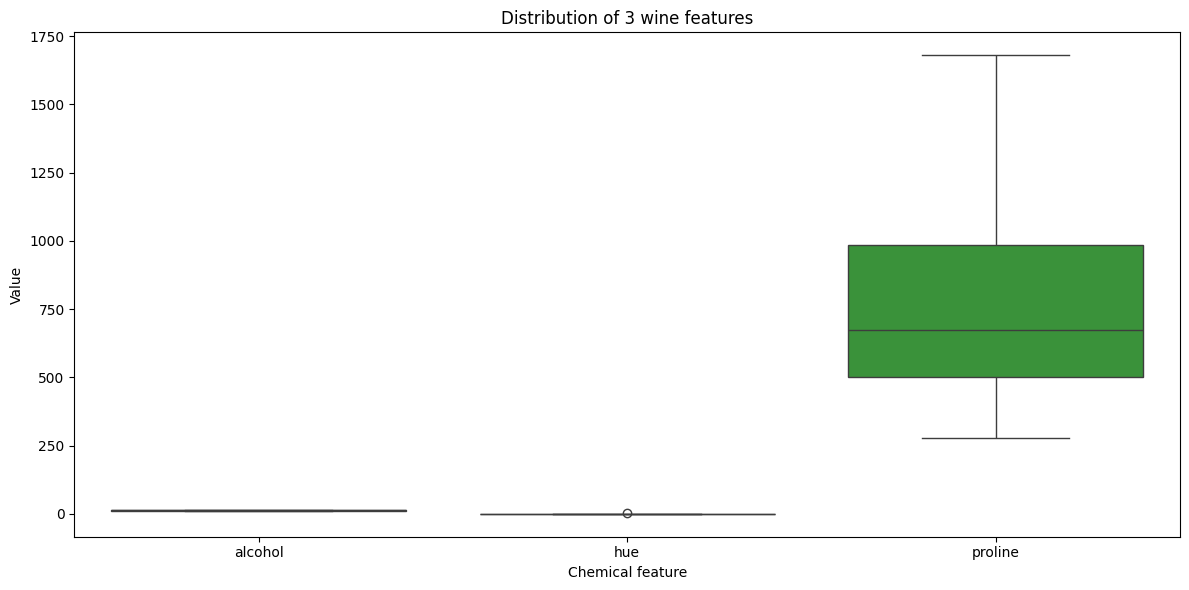

In [13]:
plt.figure(figsize=(12,6))

sns.boxplot(data=X[['alcohol','hue','proline']])

plt.title("Distribution of 3 wine features")
plt.xlabel("Chemical feature")
plt.ylabel("Value")

plt.tight_layout()
plt.show()

### 3. Split the data

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
print("Training samples: ", X_train.shape[0])
print("Testing samples: ", X_test.shape[0])

Training samples:  142
Testing samples:  36


In [16]:
print("Training class Distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

Training class Distribution:
target
0    0.331
1    0.401
2    0.268
Name: proportion, dtype: float64


In [17]:
print("Testing class Distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Testing class Distribution:
target
0    0.333
1    0.389
2    0.278
Name: proportion, dtype: float64


### 4. Baseline KNN
Start with \(k=5\) and no scaling. The model predicts the majority class among the five nearest training samples.

In [18]:
knn_baseline = KNeighborsClassifier(n_neighbors=5)

knn_baseline.fit(X_train,y_train)

y_pred_baseline = knn_baseline.predict(X_test)

In [19]:
baseline_accuracy = accuracy_score(y_test,y_pred_baseline)

print("Baseline Accuracy: ", baseline_accuracy)

Baseline Accuracy:  0.8055555555555556


In [20]:
print("Classification Report:")
print(classification_report(y_test,y_pred_baseline))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.77      0.71      0.74        14
           2       0.64      0.70      0.67        10

    accuracy                           0.81        36
   macro avg       0.80      0.80      0.80        36
weighted avg       0.81      0.81      0.81        36



### 5. KNN with scaling

In [21]:
knn_scaled = Pipeline([
    ('scaler', StandardScaler()),
    ('knn',KNeighborsClassifier(n_neighbors=5))
])

In [22]:
knn_scaled.fit(X_train,y_train)

y_pred_scaled = knn_scaled.predict(X_test)

In [23]:
scaled_accuracy = accuracy_score(y_test,y_pred_scaled)

print("Scaled KNN Accuracy: ", scaled_accuracy)

Scaled KNN Accuracy:  0.9722222222222222


In [24]:
print("Classification Report:")
print(classification_report(y_test,y_pred_scaled))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      0.93      0.96        14
           2       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



### 6. Hyperparameter tuning

In [25]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ("knn",KNeighborsClassifier())
])

In [26]:
param_grid = {
    "knn__n_neighbors":list(range(1,26,2)),
    "knn__weights":["uniform","distance"],
    "knn__p":[1,2]
}

In [27]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv = cv,
    n_jobs=-1,
    return_train_score=True
)

In [28]:
grid_search.fit(X_train,y_train)

print("Best parameters:")
print(grid_search.best_params_)

Best parameters:
{'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}


In [29]:
print("Best cross-validation accuracy")
print(round(grid_search.best_score_,4))

Best cross-validation accuracy
0.9788


#### 6.1 Cross-validation results

In [30]:
cv_results = pd.DataFrame(grid_search.cv_results_)

best_by_k = (
    cv_results
    .groupby("param_knn__n_neighbors")["mean_test_score"]
    .max()
)

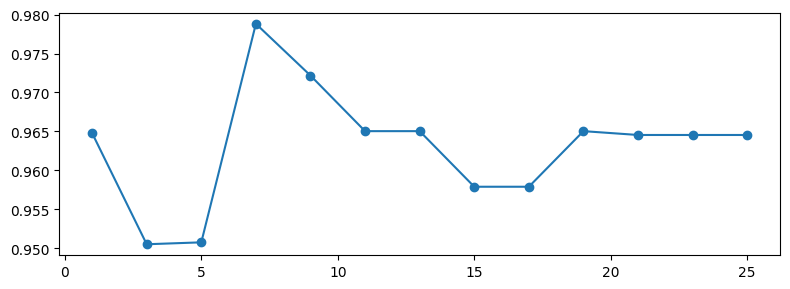

In [31]:
plt.figure(figsize=(8,3))

plt.plot(
    best_by_k.index.astype(int),
    best_by_k.values,
    marker="o"
)

plt.tight_layout()
plt.show()

### 7. Final evaluation
Evaluate the selected model on the test set using accuracy, the classification report, and the confusion matrix. A perfect score on this small test set does not guarantee perfect performance on new data.

In [32]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test)

In [33]:
best_accuracy = accuracy_score(y_test,y_pred_best)

print("Test Accuracy: ", best_accuracy)

Test Accuracy:  1.0


In [34]:
print("Classification Report:")
print(classification_report(y_test,y_pred_best))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



In [35]:
print("Confusion Matrix:")
print(confusion_matrix(y_test,y_pred_best))

Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]
